# 2026 Senate Forecast — DadBod (Literal)

**DadBod** is the third model. It's as slim as Ozempic (a short list of team-set weights), but with more safeguards: it trusts polls more when a race has more of them, penalizes one pollster flooding a state, corrects for known pollster leans, finds Kalshi markets on its own, and adds Kalshi's live polling averages as a source for the national numbers. Checks and stress tests live in the companion notebook **`Model Testing.ipynb`** in this folder.

**Literal variant:** fundamentals are the blackboard formula taken at face value: a weighted average of the state's 2024 result, the generic ballot, and presidential approval (8 : 4 : 1). The other variant lives in the sibling folder; `Models/DadBod_Model/README.md` compares them.

### What it produces
1. **P(Democrats hold at least 51 seats)** in the Senate (with a Republican vice president, 51 is the number Democrats need for control)
2. **The predicted number of Democratic seats** (the average over all simulated elections, counting independents who caucus with Democrats)

### The model in one line
For each of the 35 races:

$$\text{margin} = \frac{W_P \cdot r \cdot \text{polls} + W_F \cdot \text{fundamentals} + W_K \cdot \text{Kalshi}}{W_P \cdot r + W_F + W_K}$$

| Symbol | What it is | Set by |
|---|---|---|
| margin | Expected Democratic lead in points (negative = Republican lead) | — |
| polls | Weighted average of the race's recent polls (Step 2) | — |
| fundamentals | What we'd expect with no polls: 2024 result + national mood + incumbency (Step 4) | — |
| Kalshi | The prediction market's win probability, turned into a margin (Step 5) | — |
| W_P, W_F, W_K | How much the team trusts each source | `W_POLLS`, `W_FUNDAMENTALS`, `W_KALSHI` |
| r | Poll reliability, 0–1: how much of W_P a race earns given how much polling it has (Step 6) | `POLL_RELIABILITY` |

Each race's margin then becomes a range of possible outcomes, and the whole election is simulated `N_SIMS` times (default 10,000) with related states moving together (Step 6). Counting seats in every simulation gives the two numbers above.

### How to use
1. Run the **install** cell once per computer.
2. Change anything in **CONFIG** (each line says what it does). The next cell shows the formula with your numbers filled in.
3. *Run All.* Results land in `Output/` in this folder.
4. Open **`Model Testing.ipynb`** to check the run and see which settings matter most.

All margins are **Democrat (or a credible independent) minus Republican**, in percentage points. D+3 means the Democrat leads by 3.

## Glossary (plain English)

| Term | Meaning |
|---|---|
| **Margin** | Democratic % minus Republican %. D+4 = Democrat ahead by 4 points; R+4 = Republican ahead by 4. |
| **Poll** | A survey of a few hundred to a few thousand people, used to estimate how the whole state will vote. |
| **Sample size (n)** | How many people a poll interviewed. Bigger samples have less random error. |
| **LV / RV / A** | Who was polled: *likely voters* (screened for being likely to vote), *registered voters*, or *all adults*. LV is closest to who actually votes. |
| **Pollster grade** | VoteHub's report card (A+ to D) for how accurate a polling firm has been. Many firms have no grade. |
| **House effect** | A pollster's typical lean: how far its results usually land from the final result, and in which direction (e.g. "R+1.4" leans Republican). |
| **Partisan poll** | A poll paid for by a party or campaign. These usually flatter their sponsor. |
| **Flooding** | One firm releasing many polls of the same race, which would let it dominate the average. |
| **Generic ballot** | The national question "would you vote for the Democrat or the Republican for Congress?" Used as a read on the national mood. |
| **Approval / net approval** | % who approve of the president's job; *net* = approve − disapprove. |
| **Fundamentals** | What we'd expect in a race before looking at its polls: past results, the national mood, incumbency. |
| **Incumbent** | The senator currently holding the seat, if they are running again. Incumbents usually get a small boost. |
| **Kalshi** | A regulated prediction market where people trade on outcomes. A price of 0.64 means the market gives about a 64% chance. |
| **Simulation** | One made-up election drawn from the model's ranges. Running 10,000 of them shows how often each outcome happens. |
| **Correlation** | When states tend to miss in the same direction (a polling error in Ohio usually shows up in Michigan too). |
| **Backtest** | Re-running the model as if it were an earlier date, using only what was known then (`AS_OF_DATE`). |

## Setup: install packages
Run once per computer (safe to re-run; packages you already have are skipped). Installs everything this notebook and `Model Testing.ipynb` need that doesn't ship with Python. Restart the kernel if anything was newly installed.

In [1]:
%pip install --quiet numpy pandas scipy matplotlib jinja2 nbformat

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import copy
import json
import re
import unicodedata
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from IPython.display import Markdown, display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

## CONFIG — the team's settings

Everything the team might want to change is here. Each line has a note on what it means and what raising or lowering it does. Change a value, then *Run All*.

**Weights are relative.** `W_POLLS = 10, W_FUNDAMENTALS = 5` means polls count twice as much as fundamentals. 20 and 10 would mean exactly the same.

In [3]:
CONFIG = {
    # ---------------- Run ----------------
    "AS_OF_DATE": None, # None = today. "2026-10-15" = backtest: only polls RELEASED by then count, Kalshi race prices are
                        # that day's close, and the national numbers use polls only (Kalshi's national averages are skipped)
    "N_SIMS": 10_000, # number of simulated elections. More = smoother numbers but slower. 10,000 gives about +/-0.5 pt on P(51+)

    # ---------------- Final blend for each race ----------------
    "W_POLLS": 10, # trust in the race's own polls
    "W_FUNDAMENTALS": 5, # trust in the "no polls" expectation (2024 result + national mood + incumbency)
    "W_KALSHI": 1, # trust in the Kalshi market for that race. Low on purpose; 0 = Kalshi is shown for comparison only
    "POLL_RELIABILITY": "auto", # how much of W_POLLS a race earns given how much polling it has (Step 6):
                                #   "auto" = from the model's own error sizes (best practice): 1 poll -> 45%, 3 -> 71%, 9 -> 88%
                                #   a number k (e.g. 3) = simpler rule: a race reaches half its poll weight at k effective polls
                                #   0 = off: every race with any poll gets the full W_POLLS (how Ozempic works)

    # ---------------- Which polls count ----------------
    "WINDOW_DAYS": 28, # only polls that ended in the last this-many days count
    "WINDOW_OLDEST_WEIGHT": 0.25, # weight of a poll exactly WINDOW_DAYS old; weight falls in a straight line from 1.0 today

    # ---------------- How much each poll counts ----------------
    "POPULATION_WEIGHTS": {"LV": 1.0, "RV": 0.9, "A": 0.8}, # likely voters : registered voters : all adults (1 : 0.9 : 0.8)
    "REFERENCE_SAMPLE": 800, # a poll of this many people gets sample-size weight 1.0 (only rescales; doesn't change rankings)
    "SAMPLE_SIZE_EXPONENT": 0.5, # sample-size weight = (n / REFERENCE_SAMPLE) ^ this. 0.5 (square root) = statistics default,
                                 #   since poll error shrinks with sqrt(n); 0 = ignore size; 1 = a 1,600 poll counts 2x an 800 poll
    "SAMPLE_SIZE_CAP": 2500, # polls bigger than this count as this big (stops huge online panels from dominating)
    "MISSING_SAMPLE_SIZE": 600, # size assumed when a poll doesn't report one
    "FLOOD_EXPONENT": 0.5, # a pollster with k polls of the same race gets 1/k^this per poll. 0 = no penalty;
                           #   0.5 = its k polls together count like sqrt(k) polls; 1 = the pollster counts once in total
    "PARTISAN_SHIFT": 3.0, # points moved AGAINST the sponsor of a party/campaign poll (R-paid poll -> 3 pts toward D)
    "UNRATED_POLLSTERS": "random", # pollsters VoteHub hasn't graded: "random" = in EVERY simulation each gets the grade, error
                                   #   and lean of a randomly drawn graded pollster (redrawn every simulation); "fixed" = lowest grade
    "HOUSE_EFFECTS": True, # True = subtract each graded pollster's known lean (VoteHub scorecard) from its polls. Skipped for
                           #   partisan polls (they already get PARTISAN_SHIFT). Independent of CORRELATED_ERRORS below

    # ---------------- National signals (generic ballot + approval) ----------------
    "NAT_KALSHI_POLL_EQUIV": 5, # Kalshi's live polling averages (RCP + VoteHub approval, VoteHub generic ballot) are blended
                                #   with the individual VoteHub polls as if they were this many polls. Higher = lean more on
                                #   the market averages; 0 = ignore them. They're always used (not only when polls are thin)

    # ---- Fundamentals (Literal variant) ----
    # fundamentals = (W_STATE_2024 x 2024 state margin + W_GENERIC_BALLOT x generic ballot + W_APPROVAL x approval margin)
    #                / (sum of the three weights)  +/- incumbency
    "W_STATE_2024": 8, # weight of how the state voted for president in 2024 ("heavily"; blackboard 8)
    "W_GENERIC_BALLOT": 4, # weight of the generic congressional ballot ("heavily"; blackboard 4)
    "W_APPROVAL": 1, # weight of presidential approval ("general sentiment ... weighted less")

    # ---------------- Incumbency ----------------
    "INCUMBENCY_PTS": 3.0, # points toward the party of an incumbent senator on the ballot (elected or appointed); open seats get 0

    # ---------------- Uncertainty ----------------
    "CORRELATED_ERRORS": True, # True = when polls miss, assume fundamentals and Kalshi tend to miss the same way, so each race's
                               #   range is wider (~15%). Independent of HOUSE_EFFECTS: both, either, or neither can be on
    "SOURCE_ERROR_CORR": 0.3, # how strongly they miss together when CORRELATED_ERRORS is on (0 = independent, 1 = identical)
}

### Shared settings from `run_all.py`
When `run_all.py` runs every model for a comparison, it makes them all use the same date (today's system date) and the same number of simulations (10,000). It does this through two environment variables, which this cell reads. **When you run this notebook yourself, nothing is set and your CONFIG values are used.**

In [4]:
import os
if os.environ.get("FORECAST_AS_OF"): # set only by run_all.py
    CONFIG["AS_OF_DATE"] = os.environ["FORECAST_AS_OF"]
if os.environ.get("FORECAST_N_SIMS"):
    CONFIG["N_SIMS"] = int(os.environ["FORECAST_N_SIMS"])
if os.environ.get("FORECAST_AS_OF") or os.environ.get("FORECAST_N_SIMS"):
    print(f"run_all.py overrides: AS_OF_DATE = {CONFIG['AS_OF_DATE']}, N_SIMS = {CONFIG['N_SIMS']:,}")

run_all.py overrides: AS_OF_DATE = 2026-10-29, N_SIMS = 10,000


### The formula with your current settings
This cell rewrites the model formula with the numbers from CONFIG above, so anyone can see exactly what this run does.

In [5]:
def render_formula(cfg):
    wp, wf, wk = cfg["W_POLLS"], cfg["W_FUNDAMENTALS"], cfg["W_KALSHI"]
    tot = wp + wf + wk
    rel = cfg["POLL_RELIABILITY"]
    rel_txt = ("r = poll reliability from the model's own error sizes (1 poll → 45%, 3 → 71%, 9 → 88%)" if rel == "auto"
               else "r = 1 (reliability off: any polling gets the full poll weight)" if float(rel) == 0
               else f"r = n_eff / (n_eff + {rel}) (half the poll weight at {rel} effective polls)")
    inc_txt = f"± {cfg['INCUMBENCY_PTS']:g} incumbency" if cfg["INCUMBENCY_PTS"] else "(no incumbency bonus)"
    fund = (f"fundamentals = ({cfg['W_STATE_2024']}·2024 state margin + {cfg['W_GENERIC_BALLOT']}·generic ballot + "
        f"{cfg['W_APPROVAL']}·approval margin) / {cfg['W_STATE_2024'] + cfg['W_GENERIC_BALLOT'] + cfg['W_APPROVAL']} {inc_txt}")
    lines = [
        f"**margin** = ({wp}·r·polls + {wf}·fundamentals + {wk}·Kalshi) / ({wp}·r + {wf} + {wk})",
        f"- With plenty of polls (r ≈ 1): polls {wp/tot:.0%}, fundamentals {wf/tot:.0%}, Kalshi {wk/tot:.0%}",
        f"- {rel_txt}",
        f"- {fund}",
        f"- polls = last {cfg['WINDOW_DAYS']} days, recency weight 1.0 → {cfg['WINDOW_OLDEST_WEIGHT']}; LV:RV:A = "
        + ":".join(f"{v:g}" for v in cfg["POPULATION_WEIGHTS"].values())
        + f"; sample size (n/{cfg['REFERENCE_SAMPLE']})^{cfg['SAMPLE_SIZE_EXPONENT']} capped at {cfg['SAMPLE_SIZE_CAP']:,}"
        + f"; flooding 1/k^{cfg['FLOOD_EXPONENT']}; partisan shift {cfg['PARTISAN_SHIFT']:g} pts"
        + f"; house effects {'on' if cfg['HOUSE_EFFECTS'] else 'off'}; ungraded pollsters {cfg['UNRATED_POLLSTERS']}",
        f"- national signals: VoteHub polls + Kalshi averages counted as {cfg['NAT_KALSHI_POLL_EQUIV']} polls",
        f"- uncertainty: source errors {'correlated (ρ = ' + str(cfg['SOURCE_ERROR_CORR']) + ')' if cfg['CORRELATED_ERRORS'] else 'independent'}"
        f"; {cfg['N_SIMS']:,} simulations" + (f"; backtest as of {cfg['AS_OF_DATE']}" if cfg["AS_OF_DATE"] else ""),
    ]
    display(Markdown("\n".join(lines)))


render_formula(CONFIG)

**margin** = (10·r·polls + 5·fundamentals + 1·Kalshi) / (10·r + 5 + 1)
- With plenty of polls (r ≈ 1): polls 62%, fundamentals 31%, Kalshi 6%
- r = poll reliability from the model's own error sizes (1 poll → 45%, 3 → 71%, 9 → 88%)
- fundamentals = (8·2024 state margin + 4·generic ballot + 1·approval margin) / 13 ± 3 incumbency
- polls = last 28 days, recency weight 1.0 → 0.25; LV:RV:A = 1:0.9:0.8; sample size (n/800)^0.5 capped at 2,500; flooding 1/k^0.5; partisan shift 3 pts; house effects on; ungraded pollsters random
- national signals: VoteHub polls + Kalshi averages counted as 5 polls
- uncertainty: source errors correlated (ρ = 0.3); 10,000 simulations; backtest as of 2026-10-29

## SETTINGS — plumbing and fixed constants

Not meant for tuning: file locations, web addresses, the Senate map, and error sizes carried over from Model 1 so all three models are comparable. The `*_FALLBACK` tables are **only a check and a backup**. Kalshi markets and nominee names are found automatically each run (Step 1), and these tables are used only if that search fails or comes back with a party name instead of a candidate.

In [6]:
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Data").is_dir()) # first folder up with Data/
MODEL_ROOT = REPO_ROOT / "Models" / "DadBod_Model"

SETTINGS = {
    "DATA_DIR": REPO_ROOT / "Data",
    "OUT_DIR": MODEL_ROOT / "DadBod_Literal" / "Output",
    "CACHE_DIR": MODEL_ROOT / "Data_Cache", # shared by both DadBod variants
    "PRES_2024_FILE": "pres_2024_results.csv", # Harris/Trump % by state (certified results)
    "LEANS_FILE": "leans_and_regions.csv", # Region + PartisanLean, used only for which states move together
    "SCORECARD_FILE": "votehub_pollster_scorecards.csv", # VoteHub grade, percent error, house effect
    "ELECTION_DAY": "2026-11-03",
    "SEED": 2026, # random seed: same seed + same data = same numbers every run

    # ---- APIs ----
    "VOTEHUB_URL": "https://api.votehub.com/polls",
    "KALSHI_URL": "https://api.elections.kalshi.com/trade-api/v2",
    "USER_AGENT": "DACSS-Team5-forecast",
    "KALSHI_SENATE_SERIES_PATTERN": r"(KX)?SENATE[A-Z]{2}S?", # Kalshi series searched for "<State> Senate winner?" events
    "KALSHI_CONTROL_SERIES": "CONTROLS", # Senate-control market series ("Will Democrats win the U.S. Senate?")
    "KALSHI_CONTROL_FALLBACK": "CONTROLS-2026-D",
    # National polling-average markets: (signal, whose average, Kalshi series). The open event in each series is found each run.
    "KALSHI_NATIONAL_SERIES": [("approval", "RCP", "KXTRUMPAPPROVE"), ("approval", "VoteHub", "KXTRUMPVH"),
                               ("generic_ballot", "VoteHub", "KXGENERICBALLOTVOTEHUB")],
    "KALSHI_UPDOWN_SD": 0.5, # for weekly "above X%?" markets: typical size (pts) of a week's move in a polling average
    "KALSHI_PROB_CLIP": (0.01, 0.99), # keep implied margins finite for 99%+ markets
    "KALSHI_HISTORY_START": "2026-06-01", # first day of daily price history pulled for backtests

    # ---- Senate map (same as Model 1) ----
    "SEATS_UP": {
        "Alabama": "R", "Alaska": "R", "Arkansas": "R", "Florida": "R", "Idaho": "R",
        "Iowa": "R", "Kansas": "R", "Kentucky": "R", "Louisiana": "R", "Maine": "R",
        "Mississippi": "R", "Montana": "R", "Nebraska": "R", "North Carolina": "R",
        "Ohio": "R", "Oklahoma": "R", "South Carolina": "R", "South Dakota": "R",
        "Tennessee": "R", "Texas": "R", "West Virginia": "R", "Wyoming": "R",
        "Colorado": "D", "Delaware": "D", "Georgia": "D", "Illinois": "D",
        "Massachusetts": "D", "Michigan": "D", "Minnesota": "D", "New Hampshire": "D",
        "New Jersey": "D", "New Mexico": "D", "Oregon": "D", "Rhode Island": "D",
        "Virginia": "D",
    },
    "HOLDOVER_D": 34, "HOLDOVER_R": 31, # seats NOT on the ballot this year
    "D_SEATS_FOR_CONTROL": 51, # Republican vice president breaks 50-50 ties
    "INDEPENDENT_CAUCUS_PROB_D": {"Nebraska": 0.8}, # P(Osborn caucuses with Democrats if he wins), as in Model 1
    "INCUMBENT_STATUS": { # anything not listed = incumbent running
        "Illinois": "open", "Michigan": "open", "Minnesota": "open", "New Hampshire": "open",
        "Alabama": "open", "Iowa": "open", "Kentucky": "open", "Montana": "open",
        "North Carolina": "open", "Wyoming": "open", "Oklahoma": "open", "Texas": "open", "Louisiana": "open",
        "Florida": "appointed", "Ohio": "appointed", "South Carolina": "appointed",
    },

    # ---- FALLBACK / CHECK tables (checked Oct 26). Used only if the automatic Kalshi search misses a race or lists a party
    # ---- name instead of a candidate. The Model Testing notebook flags any disagreement with what the search found.
    "NOMINEES_FALLBACK": { # (opposition, Republican); opposition None = highest-polling non-Republican in each poll
        "Alabama": ("Everett Wess", "Barry Moore"), "Alaska": ("Mary Peltola", "Dan Sullivan"),
        "Arkansas": ("Hallie Shoffner", "Tom Cotton"), "Colorado": ("John Hickenlooper", "Mark Baisley"),
        "Delaware": ("Chris Coons", "Michael Katz"), "Florida": ("Angie Nixon", "Ashley Moody"),
        "Georgia": ("Jon Ossoff", "Mike Collins"), "Idaho": (None, "Jim Risch"),
        "Illinois": ("Juliana Stratton", "Don Tracy"), "Iowa": ("Josh Turek", "Ashley Hinson"),
        "Kansas": ("Adam Hamilton", "Roger Marshall"), "Kentucky": ("Charles Booker", "Andy Barr"),
        "Louisiana": ("Jamie Davis", "Julia Letlow"), "Maine": ("Troy Jackson", "Susan Collins"),
        "Massachusetts": ("Ed Markey", "John Deaton"), "Michigan": ("Abdul El-Sayed", "Mike Rogers"),
        "Minnesota": ("Peggy Flanagan", "Michele Tafoya"), "Mississippi": ("Scott Colom", "Cindy Hyde-Smith"),
        "Montana": (None, "Kurt Alme"), "Nebraska": ("Dan Osborn", "Pete Ricketts"),
        "New Hampshire": ("Chris Pappas", "John Sununu"), "New Jersey": ("Cory Booker", "Justin Murphy"),
        "New Mexico": ("Ben Ray Lujan", "Larry Marker"), "North Carolina": ("Roy Cooper", "Michael Whatley"),
        "Ohio": ("Sherrod Brown", "Jon Husted"), "Oklahoma": ("N'Kiyla Thomas", "Kevin Hern"),
        "Oregon": ("Jeff Merkley", "David Brock Smith"), "Rhode Island": ("Jack Reed", "Raymond McKay"),
        "South Carolina": ("Annie Andrews", "Darline Graham"), "South Dakota": (None, "Mike Rounds"),
        "Tennessee": ("Marquita Bradshaw", "Bill Hagerty"), "Texas": ("James Talarico", "Ken Paxton"),
        "Virginia": ("Mark Warner", "Bert Mizusawa"), "West Virginia": ("Rachel Fetty Anderson", "Shelley Moore Capito"),
        "Wyoming": ("James Byrd", "Harriet Hageman"),
    },
    "KALSHI_EVENTS_FALLBACK": { # Kalshi's tickers are inconsistent (Kentucky = SENATELA-26!), which is why the search goes by title
        "Alabama": "SENATEAL-26", "Alaska": "SENATEAK-26", "Arkansas": "SENATEAR-26", "Colorado": "SENATECO-26",
        "Delaware": "SENATEDE-26", "Florida": "SENATEFLS-26", "Georgia": "SENATEGA-26", "Idaho": "SENATEID-26",
        "Illinois": "SENATEIL-26", "Iowa": "SENATEIA-26", "Kansas": "SENATEKS-26", "Kentucky": "SENATELA-26",
        "Louisiana": "KXSENATELA-26NOV", "Maine": "SENATEME-26", "Massachusetts": "SENATEMA-26",
        "Michigan": "SENATEMI-26", "Minnesota": "SENATEMN-26", "Mississippi": "SENATEMS-26", "Montana": "SENATEMT-26",
        "Nebraska": "SENATENE-26", "New Hampshire": "SENATENH-26", "New Jersey": "SENATENJ-26",
        "New Mexico": "SENATENM-26", "North Carolina": "SENATENC-26", "Ohio": "SENATEOHS-26",
        "Oklahoma": "SENATEOK-26", "Oregon": "SENATEOR-26", "Rhode Island": "SENATERI-26",
        "South Carolina": "SENATESC-26", "South Dakota": "SENATESD-26", "Tennessee": "SENATETN-26",
        "Texas": "SENATETX-26", "Virginia": "SENATEVA-26", "West Virginia": "SENATEWV-26", "Wyoming": "SENATEWY-26",
    },

    # ---- National signals ----
    "NAT_MIN_POLLS": 5, # if fewer VoteHub polls than this fall in the window, the most recent this-many are used instead
    "NAT_MIX_LOOKBACK_DAYS": 90, # window for measuring the typical undecided share (approval) and D+R share (generic ballot)
    "ENV_SLOPE": 0.35, # points of Senate margin per point of net approval (Model 1 default)
    "NAT_PARTISAN_WEIGHT": 0.6, # weight of party-sponsored national polls (Model 1 default)
    "GB_POPULATION_PREFERENCE": ["LV", "RV", "A"], # one survey released for several populations -> keep the most voter-like
    "NAT_2024_MARGIN": -1.48, # overwritten from the data file below

    # ---- Poll handling (Model 1 defaults) ----
    "OTHER_TO_UNDECIDED_H2H": 1.0, "OTHER_TO_UNDECIDED_FULL_FIELD": 0.5,
    "GRADE_TO_RANK": {"A+": 10, "A": 9, "B": 8, "C": 7, "D": 6, "F": 5}, # VoteHub grade -> 5-10 scale
    "UNRATED_RANK": 5, "MIN_QUALITY_WEIGHT": 0.5, # rank 5 counts half as much as rank 10
    "ACCURACY_WEIGHT_CLIP": (0.5, 2.0), # accuracy weight = (median error / pollster error)^2, clipped
    "SINGLE_POLL_SD": 5.0, # typical error of one poll (Model 1: 1.25 x 4-pt typical miss)
    "SYSTEMATIC_POLL_ERROR_SD": 4.5, # error shared by ALL polls of a state (doesn't shrink with more polls)
    "UNDECIDED_SPLIT_SD": 0.15,
    "FUNDAMENTALS_SD": 7.5, # how far a race can stray from its fundamentals (Model 1's PRIOR_SD)
    "INDEPENDENT_SD_MULT": 1.3,

    # ---- Simulation (Model 1 defaults) ----
    "DAILY_DRIFT_SD": 0.25, "T_DF": 5,
    "CORR_NATIONAL": 0.45, "CORR_REGION": 0.15, "CORR_LEAN": 0.15, "LEAN_SCALE": 10,
    "RATING_TOSSUP": 0.60, "RATING_LEAN": 0.75, "RATING_LIKELY": 0.95,
}
S = SETTINGS


def validate(cfg, S):
    assert min(cfg["W_POLLS"], cfg["W_FUNDAMENTALS"], cfg["W_KALSHI"]) >= 0 and cfg["W_POLLS"] + cfg["W_FUNDAMENTALS"] > 0
    assert cfg["POLL_RELIABILITY"] == "auto" or float(cfg["POLL_RELIABILITY"]) >= 0, "POLL_RELIABILITY: 'auto' or a number >= 0"
    assert 0 <= cfg["WINDOW_OLDEST_WEIGHT"] <= 1 and cfg["WINDOW_DAYS"] > 0
    assert cfg["UNRATED_POLLSTERS"] in ("random", "fixed")
    assert 0 <= cfg["SOURCE_ERROR_CORR"] < 1 and cfg["NAT_KALSHI_POLL_EQUIV"] >= 0 and int(cfg["N_SIMS"]) >= 100
    assert S["HOLDOVER_D"] + S["HOLDOVER_R"] + len(S["SEATS_UP"]) == 100


validate(CONFIG, S)
S["OUT_DIR"].mkdir(parents=True, exist_ok=True)
S["CACHE_DIR"].mkdir(parents=True, exist_ok=True)
print(f"repo root: {REPO_ROOT} | outputs -> {S['OUT_DIR']}")

repo root: C:\Users\markg\OneDrive\Desktop\DACCS\2026_Midterm_Forecast | outputs -> C:\Users\markg\OneDrive\Desktop\DACCS\2026_Midterm_Forecast\Models\DadBod_Model\DadBod_Literal\Output


## Step 1: Pull the data

**In plain English:** download the latest polls and market prices. If a website is down, use the last copy saved in `Data_Cache/`, and say so.

| Source | What | Saved copy |
|---|---|---|
| VoteHub `us-senator` | Every 2026 Senate poll VoteHub has (state, pollster, dates, sample, results) | `votehub_senate_cache.csv` |
| VoteHub `generic-ballot` | National "which party for Congress?" polls | `votehub_generic_ballot_cache.csv` |
| VoteHub `approval` (Donald Trump) | Presidential approval polls | `votehub_approval_cache.csv` |
| Kalshi Senate markets | Every race's market, **found automatically** by its title ("Maine Senate winner?"), with candidate names and prices, plus the Senate-control market | `kalshi_races_cache.csv` |
| Kalshi national markets | Today's polling-average markets: RCP approval, VoteHub approval, VoteHub generic ballot | `kalshi_national_cache.csv` |
| Kalshi price history | Daily closing prices, pulled only for backtests (`AS_OF_DATE`) | `kalshi_history_cache.csv` |
| `Data/` files | 2024 results, VoteHub pollster scorecards, state regions | — |

**Why search Kalshi by title?** Kalshi's market codes aren't consistent. Kentucky's race is filed under `SENATELA-26` (LA = Louisiana!) and Louisiana's under `KXSENATELA-26NOV`. Searching the Senate series for events titled "*State* Senate winner?" in 2026 finds the right market regardless of its code. The hand table in SETTINGS is used only for races the search misses, and Model Testing flags any disagreement.

In [7]:
SOURCE_STATUS = {} # name -> "live" or "cache (...)"; read by Model Testing


def http_json(url, timeout=20):
    req = urllib.request.Request(url, headers={"User-Agent": S["USER_AGENT"], "Accept": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return json.load(r)


def with_cache(name, fetch, parse_dates):
    """Run fetch(); save to the cache on success, read the cache on failure."""
    path = S["CACHE_DIR"] / name
    try:
        df = fetch()
        if df is None or df.empty:
            raise ValueError("empty result")
        df.to_csv(path, index=False)
        SOURCE_STATUS[name] = "live"
        print(f"{name}: fetched {len(df)} rows live")
    except Exception as e:  # network down, API changed, ...
        if not path.exists():
            raise RuntimeError(f"{name}: API failed ({type(e).__name__}: {e}) and there is no saved copy") from e
        df = pd.read_csv(path)
        SOURCE_STATUS[name] = f"cache ({type(e).__name__})"
        print(f"{name}: API unavailable ({type(e).__name__}); using saved copy with {len(df)} rows")
    for c in parse_dates:
        if c in df.columns:
            df[c] = pd.to_datetime(df[c])
    return df


# ---------------- VoteHub ----------------
def fetch_senate():
    rows = []
    for p in http_json(f"{S['VOTEHUB_URL']}?poll_type=us-senator"):
        subj = str(p.get("subject") or "")
        if not subj.startswith("2026 ") or subj.endswith((" Democratic", " Republican")):
            continue # 2026 general-election polls only (drop primaries)
        state = subj[5:]
        if state not in S["SEATS_UP"]:
            continue
        rows.append({"id": p.get("id"), "end_date": p.get("end_date"), "created_at": p.get("created_at"),
                     "state": state, "pollster": p.get("pollster"), "sample_size": p.get("sample_size"),
                     "population": (p.get("population") or "").lower(), "partisan": p.get("partisan") or "",
                     "internal": bool(p.get("internal")),
                     "answers": "|".join(f"{a['choice']}={a['pct']}" for a in p.get("answers", []))})
    return pd.DataFrame(rows)


NAT_COLS = {"generic-ballot": ["Dem", "Rep"], "approval": ["Approve", "Disapprove"]}


def fetch_national(poll_type, keys, extra=""):
    rows = []
    for p in http_json(f"{S['VOTEHUB_URL']}?poll_type={poll_type}{extra}"):
        ans = {a["choice"].strip().lower(): a["pct"] for a in p.get("answers", [])}
        vals = [next((v for k, v in ans.items() if k.startswith(key)), None) for key in keys]
        if None in vals:
            continue
        rows.append({"Date": p.get("end_date"), "Released": p.get("created_at"), "Pollster": p.get("pollster"),
                     **dict(zip(NAT_COLS[poll_type], vals)), "SampleSize": p.get("sample_size"),
                     "Population": (p.get("population") or "").upper(), "Partisan": bool(p.get("partisan") or p.get("internal"))})
    return pd.DataFrame(rows)


# ---------------- Kalshi ----------------
def kalshi_mid(m):
    """Mid price (0-1) of a Kalshi market; handles *_dollars (new) and cents (old) fields."""
    def f(k):
        v = m.get(k + "_dollars")
        if v not in (None, ""):
            return float(v)
        v = m.get(k)
        return None if v in (None, "") else float(v) / 100
    bid, ask, last = f("yes_bid"), f("yes_ask"), f("last_price")
    if bid and ask and ask >= bid:
        return (bid + ask) / 2
    return last


def is_live_market(m):
    return str(m.get("status", "active")).lower() in ("active", "open", "initialized", "unopened")


def fetch_kalshi_races():
    """Find each 2026 Senate race on Kalshi by its TITLE, not its ticker. Hand table only for races the search misses."""
    today = pd.Timestamp.today().strftime("%Y-%m-%d")
    series = [s["ticker"] for s in http_json(f"{S['KALSHI_URL']}/series?category=Elections&tags=Senate").get("series", [])
              if re.fullmatch(S["KALSHI_SENATE_SERIES_PATTERN"], s["ticker"])]
    found = {}
    for ser in series:
        try:
            events = http_json(f"{S['KALSHI_URL']}/events?series_ticker={ser}&status=open&with_nested_markets=true").get("events", [])
        except Exception:
            continue
        for ev in events:
            m = re.fullmatch(r"(.+?) Senate winner\?", str(ev.get("title") or "").strip())
            is_2026 = "2026" in str(ev.get("sub_title") or "") or "-26" in ev.get("event_ticker", "")
            if not m or not is_2026 or m.group(1).strip() not in S["SEATS_UP"]:
                continue
            mk = [x for x in ev.get("markets", []) if is_live_market(x)]
            if not any(x["ticker"].endswith("-R") for x in mk):
                continue
            vol = sum(float(x.get("volume_fp") or x.get("volume") or 0) for x in mk)
            st = m.group(1).strip()
            if st not in found or vol > found[st][0]: # if Kalshi has two events for one race, keep the busier one
                found[st] = (vol, ev, mk, "search")
    for st, ev_t in S["KALSHI_EVENTS_FALLBACK"].items(): # races the search missed
        if st not in found:
            try:
                j = http_json(f"{S['KALSHI_URL']}/events/{ev_t}?with_nested_markets=true")
                ev = j.get("event", {})
                mk = [x for x in (j.get("markets") or ev.get("markets", [])) if is_live_market(x)]
                found[st] = (0, {**ev, "event_ticker": ev_t}, mk, "fallback table")
            except Exception:
                pass
    rows = []
    for st, (_, ev, mk, how) in found.items():
        for x in mk:
            rows.append({"State": st, "event_ticker": ev.get("event_ticker"), "event_title": ev.get("title"),
                         "market_ticker": x["ticker"], "side": "R" if x["ticker"].endswith("-R") else "OPP",
                         "name": x.get("yes_sub_title") or x.get("subtitle"), "p_mid": kalshi_mid(x),
                         "found_by": how, "fetched": today})
    ctrl = None # Senate control market
    try:
        for ev in http_json(f"{S['KALSHI_URL']}/events?series_ticker={S['KALSHI_CONTROL_SERIES']}&status=open"
                            f"&with_nested_markets=true").get("events", []):
            if "2026" in ev.get("event_ticker", "") or "2026" in str(ev.get("sub_title") or ""):
                ctrl = next((x for x in ev.get("markets", []) if "democ" in str(x.get("yes_sub_title", "")).lower()), ctrl)
    except Exception:
        pass
    if ctrl is None:
        ctrl = http_json(f"{S['KALSHI_URL']}/markets/{S['KALSHI_CONTROL_FALLBACK']}")["market"]
    rows.append({"State": "CONTROL", "event_ticker": ctrl.get("event_ticker"), "event_title": ctrl.get("title"),
                 "market_ticker": ctrl["ticker"], "side": "D", "name": ctrl.get("yes_sub_title"), "p_mid": kalshi_mid(ctrl),
                 "found_by": "search", "fetched": today})
    return pd.DataFrame(rows)


def fetch_kalshi_national():
    """Today's polling-average markets. In each series the open event closing soonest = the current reading."""
    today = pd.Timestamp.today().strftime("%Y-%m-%d")
    rows = []
    for signal, source, ser in S["KALSHI_NATIONAL_SERIES"]:
        try:
            events = http_json(f"{S['KALSHI_URL']}/events?series_ticker={ser}&status=open&with_nested_markets=true").get("events", [])
        except Exception:
            continue
        events = [e for e in events if e.get("markets")]
        if not events:
            continue
        ev = min(events, key=lambda e: min(str(m.get("close_time") or "9") for m in e["markets"]))
        for m in ev["markets"]:
            rows.append({"signal": signal, "source": source, "series_ticker": ser, "event_ticker": ev.get("event_ticker"),
                         "market_ticker": m["ticker"], "strike_type": m.get("strike_type"), "floor_strike": m.get("floor_strike"),
                         "cap_strike": m.get("cap_strike"), "p_mid": kalshi_mid(m), "fetched": today})
    return pd.DataFrame(rows)


def candle_value(c, side):
    d = c.get(side) or {}
    if d.get("close_dollars") not in (None, ""):
        return float(d["close_dollars"])
    return None if d.get("close") in (None, "") else float(d["close"]) / 100


def fetch_kalshi_history():
    """Daily closes of every race's Republican market + the control market (one call per market)."""
    start = int(pd.Timestamp(S["KALSHI_HISTORY_START"], tz="UTC").timestamp())
    end = int(pd.Timestamp.now(tz="UTC").timestamp())
    k = DATA["kalshi_races"]
    tickers = list(k.loc[k["side"].isin(["R", "D"]), "market_ticker"])
    rows = []
    for m in tickers:
        series = m.split("-")[0]
        j = http_json(f"{S['KALSHI_URL']}/series/{series}/markets/{m}/candlesticks"
                      f"?start_ts={start}&end_ts={end}&period_interval=1440")
        for c in j.get("candlesticks", []):
            rows.append({"market_ticker": m, "end_period_ts": c["end_period_ts"], "yes_bid": candle_value(c, "yes_bid"),
                         "yes_ask": candle_value(c, "yes_ask"), "last": candle_value(c, "price")})
    return pd.DataFrame(rows)


def load_static():
    d = S["DATA_DIR"]
    pres = pd.read_csv(d / S["PRES_2024_FILE"]).set_index("State")
    pres["margin2024"] = pres["Harris_pct"] - pres["Trump_pct"] # D - R
    S["NAT_2024_MARGIN"] = float(pres.loc["National", "margin2024"])
    leans = pd.read_csv(d / S["LEANS_FILE"], encoding="utf-8-sig")
    leans = leans[leans["State"] != "Source"].assign(State=lambda x: x["State"].str.strip())
    leans["PartisanLean"] = pd.to_numeric(leans["PartisanLean"])
    cards = pd.read_csv(d / S["SCORECARD_FILE"])
    he = cards["House_Effect"].astype(str).str.strip()
    cards["house_effect_d"] = he.str[2:].astype(float) * np.where(he.str.startswith("D"), 1.0, -1.0) # + = leans Democratic
    return {"pres": pres, "leans": leans.set_index("State"), "scorecards": cards}


DATA = {
    **load_static(),
    "senate": with_cache("votehub_senate_cache.csv", fetch_senate, ["end_date", "created_at"]),
    "generic": with_cache("votehub_generic_ballot_cache.csv", lambda: fetch_national("generic-ballot", ["dem", "rep"]),
                          ["Date", "Released"]),
    "approval": with_cache("votehub_approval_cache.csv",
                           lambda: fetch_national("approval", ["approve", "disapprove"], "&subject=Donald%20Trump"),
                           ["Date", "Released"]),
    "kalshi_races": with_cache("kalshi_races_cache.csv", fetch_kalshi_races, []),
    "kalshi_national": with_cache("kalshi_national_cache.csv", fetch_kalshi_national, []),
}


def surname(name):
    s = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode().lower()
    s = re.sub(r"[^a-z\- ]", "", s).strip()
    return s.split()[-1] if s else ""


def build_nominees(data):
    """Nominees from Kalshi's market names; hand table only where Kalshi lists a party instead of a person.
    Returns {state: (republican, [opposition candidates])} plus a check table vs the hand table."""
    k = data["kalshi_races"]
    generic = lambda n: (not isinstance(n, str)) or "party" in n.lower()
    out, check = {}, []
    for st in S["SEATS_UP"]:
        g = k[k["State"] == st]
        hand_opp, hand_rep = S["NOMINEES_FALLBACK"][st]
        rep_k = [n for n in g.loc[g["side"] == "R", "name"] if not generic(n)]
        opp_k = [n for n in g.loc[g["side"] == "OPP", "name"] if not generic(n)]
        rep = rep_k[0] if rep_k else hand_rep
        opp = opp_k if opp_k else ([hand_opp] if hand_opp else [])
        source = "Kalshi" if rep_k and opp_k else ("hand table" if g.empty else "Kalshi + hand table (Kalshi lists parties)")
        agree = surname(rep) == surname(hand_rep) and (hand_opp is None or surname(hand_opp) in {surname(n) for n in opp})
        check.append({"State": st, "republican": rep, "opposition": ", ".join(opp) or "(top non-R in each poll)",
                      "source": source, "matches_hand_table": agree})
    return out_with(out, check)


def out_with(out, check):
    for row in check:
        rep = row["republican"]
        opp = [] if row["opposition"].startswith("(") else [s.strip() for s in row["opposition"].split(", ")]
        out[row["State"]] = (rep, opp)
    return out, pd.DataFrame(check).set_index("State")


if "found_by" not in DATA["kalshi_races"].columns: # saved copies written before this column existed
    DATA["kalshi_races"]["found_by"] = "saved copy"
NOMINEES, NOMINEE_CHECK = build_nominees(DATA)
kr = DATA["kalshi_races"]
KALSHI_CHECK = pd.DataFrame({
    "found_event": kr[kr["side"] == "R"].set_index("State")["event_ticker"].reindex(sorted(S["SEATS_UP"])),
    "found_by": kr[kr["side"] == "R"].set_index("State")["found_by"].reindex(sorted(S["SEATS_UP"])),
    "fallback_table": pd.Series(S["KALSHI_EVENTS_FALLBACK"]),
})
KALSHI_CHECK["matches_hand_table"] = KALSHI_CHECK["found_event"] == KALSHI_CHECK["fallback_table"]
print(f"Kalshi: {KALSHI_CHECK['found_event'].notna().sum()}/35 races found "
      f"({(KALSHI_CHECK['found_by'] == 'search').sum()} by title search); "
      f"{(~KALSHI_CHECK['matches_hand_table']).sum()} differ from the hand table; "
      f"nominees from Kalshi for {(NOMINEE_CHECK['source'] == 'Kalshi').sum()}/35 races, "
      f"{(~NOMINEE_CHECK['matches_hand_table']).sum()} differ from the hand table (details in Model Testing)")

votehub_senate_cache.csv: fetched 486 rows live


votehub_generic_ballot_cache.csv: fetched 547 rows live


votehub_approval_cache.csv: fetched 1026 rows live


kalshi_races_cache.csv: fetched 75 rows live


kalshi_national_cache.csv: fetched 11 rows live
Kalshi: 35/35 races found (25 by title search); 0 differ from the hand table; nominees from Kalshi for 34/35 races, 0 differ from the hand table (details in Model Testing)


## Step 2: State polls → one polling average per race

**In plain English:** a race might have a dozen polls of very different quality. We give each poll a weight (how much we trust it) and take the weighted average. A poll's weight is several factors multiplied together:

| Factor | Plain English | Setting |
|---|---|---|
| Recency | Newer polls count more. Weight falls in a straight line from 100% today to 25% at day 28; older polls are dropped | `WINDOW_DAYS`, `WINDOW_OLDEST_WEIGHT` |
| Sample size | Bigger polls count more, with diminishing returns: weight = (n ÷ 800)^0.5, n capped at 2,500 | `REFERENCE_SAMPLE`, `SAMPLE_SIZE_EXPONENT`, `SAMPLE_SIZE_CAP`, `MISSING_SAMPLE_SIZE` |
| Population | Likely voters 1.0, registered voters 0.9, all adults 0.8 | `POPULATION_WEIGHTS` |
| Pollster grade | VoteHub A+ counts twice as much as a D (A+ 1.0, A 0.9, B 0.8, C 0.7, D 0.6) | — |
| Accuracy | Pollsters with smaller past errors count more | — |
| Flooding | A firm with k polls of the same race gets 1/√k per poll, so it can't drown out everyone else | `FLOOD_EXPONENT` |
| Survey versions | One survey released two ways (e.g. likely and registered voters) counts once in total | — |

Two **adjustments** move a poll's *margin* (not its weight):
- **Partisan sponsor:** a poll paid for by a party or campaign is moved `PARTISAN_SHIFT` (3) points against the sponsor.
- **House effect** (`HOUSE_EFFECTS`): each graded pollster's known lean is subtracted (SurveyUSA leans D+2.3, so its polls move 2.3 toward R). Partisan polls are skipped so they aren't adjusted twice.

**Ungraded pollsters** (about half the polls): with `UNRATED_POLLSTERS = "random"`, **in every one of the simulations** each ungraded firm is given the grade, accuracy and lean of a randomly picked VoteHub-graded firm. All of that firm's polls share the pick, and it is **redrawn in the next simulation**. Over 10,000 simulations this spreads our uncertainty about these firms into the result, instead of punishing them with a fixed low grade. Tables show their *average* weight.

**Matching candidates:** VoteHub lists candidates by name, not party, so each poll is matched to the nominees from Step 1 by surname. The opposition is the highest-polling of the non-Republican nominees (the "credible independent" rule, e.g. Osborn in Nebraska). Polls missing a nominee (old hypothetical match-ups) are dropped.

In [8]:
def parse_answers(s):
    out = []
    for part in str(s).split("|"):
        if "=" in part:
            name, pct = part.rsplit("=", 1)
            out.append((name.strip(), float(pct)))
    return out


def match_poll(row):
    """(opp_pct, rep_pct, n_candidates) or None if the poll doesn't include the nominees."""
    rep_name, opp_names = NOMINEES[row["state"]]
    ans = parse_answers(row["answers"])
    rep = next((p for n, p in ans if surname(n) == surname(rep_name)), None)
    if rep is None:
        return None
    others = [(n, p) for n, p in ans if surname(n) != surname(rep_name)]
    if opp_names:
        keys = {surname(n) for n in opp_names}
        opp = max((p for n, p in others if surname(n) in keys), default=None) # highest-polling opposition nominee
    else:
        opp = max((p for _, p in others), default=None)
    return None if opp is None else (opp, rep, len(ans))


def card_table(cards):
    """quality, quality x accuracy, and house effect of every VoteHub-graded pollster (the pool random grades come from)."""
    rank = cards["Grade"].map(S["GRADE_TO_RANK"]).fillna(S["UNRATED_RANK"]).to_numpy(dtype=float)
    q = S["MIN_QUALITY_WEIGHT"] + (1 - S["MIN_QUALITY_WEIGHT"]) * (np.clip(rank, 5, 10) - 5) / 5
    a = np.clip((cards["Percent_Error"].median() / cards["Percent_Error"].to_numpy()) ** 2, *S["ACCURACY_WEIGHT_CLIP"])
    return q, q * a, cards["house_effect_d"].to_numpy(dtype=float)


def scorecard_lookup(cards):
    key = lambda s: re.sub(r"[^a-z0-9]", "", str(s).lower())
    lut = {}
    for _, r in cards.iterrows():
        names = [r["Scorecard_Name"]] + (str(r["Aliases"]).split("|") if pd.notna(r["Aliases"]) else [])
        for n in names:
            lut[key(n)] = (S["GRADE_TO_RANK"].get(r["Grade"], S["UNRATED_RANK"]), float(r["Percent_Error"]), float(r["house_effect_d"]))
    return lambda p: lut.get(key(p), (S["UNRATED_RANK"], np.nan, np.nan))


POLL_COLS = ["state", "pollster", "end_date", "age", "opp_pct", "rep_pct", "n_cands", "undecided", "margin", "undecided_sd",
             "partisan_shift", "house_effect", "adj_margin_raw", "adj_margin", "unrated", "partisan_poll",
             "w_base", "w_quality", "w_accuracy", "weight", "family"]


def prepare_polls(data, cfg, today, verbose=False):
    raw = data["senate"].copy()
    raw = raw[raw["state"].isin(S["SEATS_UP"])]
    if "created_at" in raw.columns: # backtests: only polls already PUBLISHED by `today`
        raw = raw[raw["created_at"].isna() | (raw["created_at"] <= today)]
    age = (today - raw["end_date"]).dt.days
    p = raw[(age >= 0) & (age <= cfg["WINDOW_DAYS"])].copy()
    p["age"] = (today - p["end_date"]).dt.days
    n_window = len(p)
    matched = p.apply(match_poll, axis=1) if n_window else pd.Series(dtype=object)
    keep = matched.notna().to_numpy(dtype=bool) if n_window else np.zeros(0, dtype=bool)
    p, matched = p[keep].copy(), matched[keep]
    if verbose:
        print(f"State polls: {len(raw)} general-election polls -> {n_window} in the last {cfg['WINDOW_DAYS']} days "
              f"-> {len(p)} with the nominees")
    if p.empty:
        return pd.DataFrame(columns=POLL_COLS)
    p["opp_pct"], p["rep_pct"], p["n_cands"] = [m[0] for m in matched], [m[1] for m in matched], [m[2] for m in matched]
    # margin, undecideds allocated proportionally (Model 1 rule)
    o, r = p["opp_pct"], p["rep_pct"]
    other = (100 - o - r).clip(lower=0)
    u = other * np.where(p["n_cands"] > 2, S["OTHER_TO_UNDECIDED_FULL_FIELD"], S["OTHER_TO_UNDECIDED_H2H"])
    p["undecided"] = u
    p["margin"] = (o - r) * (o + r + u) / (o + r)
    p["undecided_sd"] = 2 * u * S["UNDECIDED_SPLIT_SD"]
    # adjustments to the margin
    party = p["partisan"].fillna("").astype(str).str.upper()
    p["partisan_poll"] = party.str.startswith(("REP", "DEM"))
    p["partisan_shift"] = np.where(party.str.startswith("REP"), cfg["PARTISAN_SHIFT"],
                                   np.where(party.str.startswith("DEM"), -cfg["PARTISAN_SHIFT"], 0.0))
    p["adj_margin_raw"] = p["margin"] + p["partisan_shift"] # before house effects
    look = p["pollster"].map(scorecard_lookup(data["scorecards"]))
    p["pollster_rank"], p["pollster_error"] = [x[0] for x in look], [x[1] for x in look]
    p["pollster_house_effect"] = [x[2] for x in look]
    p["unrated"] = p["pollster_error"].isna()
    q_card, qa_card, he_card = card_table(data["scorecards"])
    he = p["pollster_house_effect"].copy()
    if cfg["UNRATED_POLLSTERS"] == "random":
        he[p["unrated"]] = he_card.mean() # average lean of the pool (simulations draw a specific one)
    he = he.fillna(0.0)
    p["house_effect"] = np.where(cfg["HOUSE_EFFECTS"] & ~p["partisan_poll"], he, 0.0)
    p["adj_margin"] = p["adj_margin_raw"] - p["house_effect"]
    # weights
    p["w_recency"] = 1 - (1 - cfg["WINDOW_OLDEST_WEIGHT"]) * p["age"] / cfg["WINDOW_DAYS"]
    n = pd.to_numeric(p["sample_size"], errors="coerce").fillna(cfg["MISSING_SAMPLE_SIZE"]).clip(upper=cfg["SAMPLE_SIZE_CAP"])
    p["w_size"] = (n / cfg["REFERENCE_SAMPLE"]) ** cfg["SAMPLE_SIZE_EXPONENT"]
    pop = p["population"].fillna("").astype(str).str.upper().replace({"ADULTS": "A", "V": "RV"})
    p["w_population"] = pop.map(cfg["POPULATION_WEIGHTS"]).fillna(1.0)
    p["w_quality"] = S["MIN_QUALITY_WEIGHT"] + (1 - S["MIN_QUALITY_WEIGHT"]) * (p["pollster_rank"].clip(5, 10) - 5) / 5
    p["w_accuracy"] = ((data["scorecards"]["Percent_Error"].median() / p["pollster_error"]) ** 2).fillna(1.0).clip(*S["ACCURACY_WEIGHT_CLIP"])
    if cfg["UNRATED_POLLSTERS"] == "random": # tables show the pool AVERAGE; simulations redraw (Step 6)
        p.loc[p["unrated"], "w_quality"] = q_card.mean()
        p.loc[p["unrated"], "w_accuracy"] = qa_card.mean() / q_card.mean()
    p["family"] = p["end_date"].dt.strftime("%Y-%m-%d") + " | " + p["state"] + " | " + p["pollster"]
    p["w_version"] = 1.0 / p.groupby("family")["family"].transform("size")
    k = p.groupby(["state", "pollster"])["family"].transform("nunique") # distinct surveys by this firm in this race
    p["w_flood"] = 1.0 / k ** cfg["FLOOD_EXPONENT"]
    p["w_base"] = p[["w_recency", "w_size", "w_population", "w_version", "w_flood"]].prod(axis=1) # all but the grade
    p["weight"] = p["w_base"] * p["w_quality"] * p["w_accuracy"]
    return p.reset_index(drop=True)


def polling_averages(p):
    rows = {}
    for st, g in p.groupby("state"):
        w = g["weight"].to_numpy(dtype=float)
        n_eff = w.sum() ** 2 / (w ** 2).sum() # "effective number of polls" (Kish): 3 equal polls = 3; 1 big + 2 tiny ~ 1.5
        und_sd = np.average(g["undecided_sd"], weights=w)
        sd = np.sqrt(S["SINGLE_POLL_SD"] ** 2 / n_eff + S["SYSTEMATIC_POLL_ERROR_SD"] ** 2 + und_sd ** 2)
        rows[st] = {"poll_mean": np.average(g["adj_margin"], weights=w), "poll_sd": sd, "n_polls": len(g), "n_eff": n_eff,
                    "last_poll_age": g["age"].min()}
    return pd.DataFrame.from_dict(rows, orient="index", columns=["poll_mean", "poll_sd", "n_polls", "n_eff", "last_poll_age"]).astype(float)

## Step 3: National signals (generic ballot + approval)

**In plain English:** the national mood feeds the fundamentals. We measure it two ways: how people answer "which party for Congress?" (the **generic ballot**) and how many approve of the president (**approval**). Each one blends two kinds of source:

1. **Individual VoteHub polls** from the window, weighted like the state polls. VoteHub's feed has had very few national polls since June. If fewer than `NAT_MIN_POLLS` (5) fall in the window, the 5 most recent are used.
2. **Kalshi's polling-average markets**, an **additional source that is always used** (not just a backup): RCP's and VoteHub's approval averages, and VoteHub's generic-ballot average. These are averages of many polls, refreshed daily, and the market price tells us where traders expect them to be.

**How they're combined** (both on the same scale):

$$\text{signal} = \frac{n_{\text{polls}} \cdot \text{poll average} + K \cdot \text{Kalshi average}}{n_{\text{polls}} + K}$$

where n_polls is the effective number of VoteHub polls and **K = `NAT_KALSHI_POLL_EQUIV`** (default 5): the Kalshi average counts as much as 5 polls. To lean more on the markets, raise K; to ignore them, set K = 0. **RCP and VoteHub approval are averaged together first** into one Kalshi approval number, then blended with the polls, because they track mostly the same polls and shouldn't be counted twice.

**Reading a value out of a Kalshi market:**
- *Bucket markets* (RCP approval: "38.2%? 38.3%? …"): the probability-weighted middle of the buckets.
- *Weekly "above X%?" markets* (VoteHub): X, nudged by how sure traders are. Value = X + Φ⁻¹(price) × 0.5, where 0.5 pts (`KALSHI_UPDOWN_SD`) is a typical week's move. A price of 0.50 means "right at X".

**Converting Kalshi approval to net approval:** the markets give only **approve %**, but the model uses **net approval** (approve − disapprove). We estimate disapprove from the share of people who answer neither:

$$\text{disapprove} = 100 - \text{approve} - U \quad\Rightarrow\quad \text{net} = 2 \cdot \text{approve} - 100 + U$$

**U** = the average of (100 − approve − disapprove) across VoteHub's approval polls from the last 90 days (`NAT_MIX_LOOKBACK_DAYS`), measured fresh each run. Example: approve 37.6%, U = 3.3 → disapprove 59.1% → net −21.5.

**Converting Kalshi's generic ballot:** VoteHub's average is the raw D − R gap; the model uses a two-party gap (as if undecideds broke evenly). Two-party = raw × 100 ÷ (D% + R%), with D% + R% averaged over recent VoteHub generic-ballot polls.

**Approval → margin:** AP = 0.35 × −(net approval) (`ENV_SLOPE`, Model 1's value): an unpopular Republican president helps Democrats.

**Backtests** (`AS_OF_DATE` set): the Kalshi national averages are skipped and polls only are used, since Kalshi's history for these weekly markets isn't reliably available.

In [9]:
def national_poll_average(df, value_fn, cfg, today):
    """Weighted average of VoteHub national polls in the window -> (value, n_polls, n_eff)."""
    if df is None or df.empty:
        return np.nan, 0, 0.0
    g = df[df["Date"] <= today].copy()
    if "Released" in g.columns:
        g = g[g["Released"].isna() | (g["Released"] <= today)]
    g["Population"] = g["Population"].fillna("").astype(str).str.upper().replace({"ADULTS": "A"})
    rank = {pop: i for i, pop in enumerate(S["GB_POPULATION_PREFERENCE"])}
    g["pop_rank"] = g["Population"].map(rank).fillna(len(rank))
    g = g.sort_values("pop_rank").drop_duplicates(["Date", "Pollster"], keep="first")
    use = g[(today - g["Date"]).dt.days <= cfg["WINDOW_DAYS"]]
    if len(use) < S["NAT_MIN_POLLS"]:
        use = g.nlargest(S["NAT_MIN_POLLS"], "Date")
    if use.empty:
        return np.nan, 0, 0.0
    a = (today - use["Date"]).dt.days.clip(lower=0, upper=cfg["WINDOW_DAYS"])
    w = 1 - (1 - cfg["WINDOW_OLDEST_WEIGHT"]) * a / cfg["WINDOW_DAYS"]
    n = pd.to_numeric(use["SampleSize"], errors="coerce").fillna(cfg["MISSING_SAMPLE_SIZE"]).replace(0, cfg["MISSING_SAMPLE_SIZE"])
    w = w * (n.clip(upper=cfg["SAMPLE_SIZE_CAP"]) / cfg["REFERENCE_SAMPLE"]) ** cfg["SAMPLE_SIZE_EXPONENT"]
    w = w * use["Population"].map(cfg["POPULATION_WEIGHTS"]).fillna(1.0)
    w = w * np.where(use["Partisan"].astype(str).str.lower().isin(["true", "1"]), S["NAT_PARTISAN_WEIGHT"], 1.0)
    w = w.to_numpy(dtype=float)
    return float(np.average(value_fn(use), weights=w)), len(use), float(w.sum() ** 2 / (w ** 2).sum())


def kalshi_implied_value(g):
    """Level of a polling average implied by one Kalshi event's prices (see the notes above)."""
    g = g.dropna(subset=["p_mid"])
    if g.empty:
        return np.nan
    fl = pd.to_numeric(g["floor_strike"], errors="coerce")
    cp = pd.to_numeric(g["cap_strike"], errors="coerce")
    if (g["strike_type"] == "greater").all(): # "above X%?" market(s)
        if len(g) == 1:
            p = float(np.clip(g["p_mid"].iloc[0], 0.02, 0.98))
            return float(fl.iloc[0] + norm.ppf(p) * S["KALSHI_UPDOWN_SD"])
        lad = pd.DataFrame({"x": fl, "p": g["p_mid"].astype(float)}).sort_values("x") # ladder: find where P(above) = 50%
        return float(np.interp(0.5, lad["p"].to_numpy()[::-1], lad["x"].to_numpy()[::-1]))
    strikes = np.sort(pd.concat([fl, cp]).dropna().unique()) # bucket market
    step = float(np.min(np.diff(strikes))) if len(strikes) > 1 else 0.1
    val = np.where(g["strike_type"] == "less", cp - step, np.where(g["strike_type"] == "greater", fl + step, (fl + cp) / 2))
    p = g["p_mid"].astype(float).to_numpy()
    return float(np.sum(p * val) / p.sum())


def national_signals(data, cfg, today):
    backtest = today < pd.Timestamp.today().normalize()
    recent = lambda df: df[(df["Date"] <= today) & (df["Date"] >= today - pd.Timedelta(days=S["NAT_MIX_LOOKBACK_DAYS"]))]
    ap, gb = data["approval"], data["generic"]
    ap_mix = recent(ap) if len(recent(ap)) >= 10 else ap[ap["Date"] <= today].nlargest(10, "Date")
    gb_mix = recent(gb) if len(recent(gb)) >= 10 else gb[gb["Date"] <= today].nlargest(10, "Date")
    U = float((100 - ap_mix["Approve"] - ap_mix["Disapprove"]).clip(lower=0).mean()) # share answering neither
    DR = float((gb_mix["Dem"] + gb_mix["Rep"]).mean()) # D% + R% in generic-ballot polls

    gb_poll, n_gb, ne_gb = national_poll_average(gb, lambda d: 100 * (d["Dem"] - d["Rep"]) / (d["Dem"] + d["Rep"]), cfg, today)
    net_poll, n_ap, ne_ap = national_poll_average(ap, lambda d: d["Approve"] - d["Disapprove"], cfg, today)

    kn = data["kalshi_national"]
    vals = {} if backtest or kn is None or kn.empty else {
        (sig, src): kalshi_implied_value(g) for (sig, src), g in kn.groupby(["signal", "source"])}
    ap_k = [v for (sig, _), v in vals.items() if sig == "approval" and not np.isnan(v)]
    gb_k = [v for (sig, _), v in vals.items() if sig == "generic_ballot" and not np.isnan(v)]
    approve_k = float(np.mean(ap_k)) if ap_k else np.nan # RCP + VoteHub combined FIRST
    net_k = 2 * approve_k - 100 + U if ap_k else np.nan
    gb_k2 = float(np.mean(gb_k)) * 100 / DR if gb_k else np.nan # raw D-R -> two-party

    K = cfg["NAT_KALSHI_POLL_EQUIV"]
    def blend(poll, n_eff, kal):
        parts = [(n_eff, poll), (K, kal)]
        parts = [(w, v) for w, v in parts if w > 0 and not np.isnan(v)]
        return sum(w * v for w, v in parts) / sum(w for w, _ in parts) if parts else np.nan

    gb_val, net_val = blend(gb_poll, ne_gb, gb_k2), blend(net_poll, ne_ap, net_k)
    table = pd.DataFrame([
        {"signal": "generic ballot (D-R, two-party)", "VoteHub polls": gb_poll, "n polls": n_gb, "effective n": ne_gb,
         "Kalshi average": gb_k2, "Kalshi counts as": K if not np.isnan(gb_k2) else 0, "combined": gb_val},
        {"signal": "net approval", "VoteHub polls": net_poll, "n polls": n_ap, "effective n": ne_ap,
         "Kalshi average": net_k, "Kalshi counts as": K if not np.isnan(net_k) else 0, "combined": net_val},
    ]).set_index("signal")
    return {"gb": gb_val, "net_approval": net_val, "appr": S["ENV_SLOPE"] * -net_val if not np.isnan(net_val) else np.nan,
            "table": table, "U": U, "DR": DR, "kalshi_approve_pct": approve_k, "kalshi_parts": vals, "backtest": backtest}

## Step 4: Fundamentals (Literal)

**In plain English:** before looking at any polls, what would we expect in each state? This variant takes a weighted average of three numbers: how the state voted for president in 2024, how the country answers "which party for Congress?", and how popular the president is. It's the formula from the blackboard, used exactly as written.

**One side effect:** the generic ballot and approval are *national* numbers, so averaging them in pulls every state partway toward the national figure. With 8 : 4 : 1, a state keeps only 8/13 ≈ 62% of its own lean (Wyoming's R+46 becomes about R+25). The README explains what that does.

$$\text{fund}_s = \frac{w_{24}\cdot\text{margin2024}_s + w_{GB}\cdot GB + w_{AP}\cdot AP}{w_{24}+w_{GB}+w_{AP}} \pm \text{incumbency}$$

| Symbol | Meaning |
|---|---|
| margin2024ₛ | Harris % − Trump % in the state in 2024 (Alabama −30.5, Maine +6.9) |
| GB | Generic ballot: national D − R margin when people are asked "which party for Congress?" (Step 3) |
| AP | Approval converted to a margin: 0.35 × −(net approval) (Step 3) |
| w_24, w_GB, w_AP | `W_STATE_2024`, `W_GENERIC_BALLOT`, `W_APPROVAL` in CONFIG |
| incumbency | `INCUMBENCY_PTS` toward the party of an incumbent on the ballot; 0 for open seats |

In [10]:
def fundamentals(races, env, cfg, S):
    """Literal: weighted average of 2024 state margin, generic ballot and approval margin, + incumbency."""
    parts = [(cfg["W_STATE_2024"], races["margin2024"]), (cfg["W_GENERIC_BALLOT"], env["gb"]), (cfg["W_APPROVAL"], env["appr"])]
    parts = [(w, v) for w, v in parts if w > 0 and v is not None and not (np.isscalar(v) and np.isnan(v))]
    total_w = sum(w for w, _ in parts)
    out = sum(w * v for w, v in parts) / total_w + races["incumbency_pts"]
    return out, {"share_of_2024_lean_kept": cfg["W_STATE_2024"] / total_w}


## Step 5: Kalshi race markets

**In plain English:** Kalshi gives each race a win probability, but the other two sources are in points. We convert the probability into "the margin that would give that probability under this model's own uncertainty for the race":

$$\text{Kalshi margin} = \Phi^{-1}(P_{\text{Kalshi}}) \times \sigma$$

Φ⁻¹ turns a probability into "how many standard deviations ahead", and σ is the race's uncertainty from polls and fundamentals. Example: Kalshi 75% with σ = 5 → D+3.4. P = 1 − P(Republican wins), so a strong independent counts as the opposition. Probabilities are clipped to 1–99%. **Backtests** use each market's closing price on the backtest date (Kalshi's daily price history), so nothing from after that date leaks in.

In [11]:
def kalshi_as_of(data, today):
    """(State, p_opp) for the run date: live prices for today, else each market's last daily close on/before that date."""
    k = data["kalshi_races"]
    rep = k[k["side"] == "R"].set_index("State")["p_mid"].astype(float)
    if today >= pd.Timestamp.today().normalize():
        out = pd.DataFrame({"p_opp": 1 - rep})
        ctrl = k.loc[k["State"] == "CONTROL", "p_mid"]
        out.loc["CONTROL", "p_opp"] = float(ctrl.iloc[0]) if len(ctrl) else np.nan
        return out
    if "kalshi_history" not in data:
        data["kalshi_history"] = with_cache("kalshi_history_cache.csv", fetch_kalshi_history, [])
    h = data["kalshi_history"]
    cutoff = (today + pd.Timedelta(days=1)).tz_localize("America/New_York").timestamp() # end of that day, Eastern
    h = h[h["end_period_ts"] <= cutoff].sort_values("end_period_ts").groupby("market_ticker").last()
    bid, ask, last = (pd.to_numeric(h[c], errors="coerce") for c in ("yes_bid", "yes_ask", "last"))
    price = pd.Series(np.where(bid.notna() & ask.notna() & (bid > 0) & (ask >= bid), (bid + ask) / 2, last), index=h.index)
    tick = k.set_index("State")
    out = {}
    for st in list(S["SEATS_UP"]) + ["CONTROL"]:
        side = "D" if st == "CONTROL" else "R"
        t = k.loc[(k["State"] == st) & (k["side"] == side), "market_ticker"]
        p = price.get(t.iloc[0], np.nan) if len(t) else np.nan
        out[st] = p if st == "CONTROL" else 1 - p
    return pd.DataFrame({"p_opp": pd.Series(out)})


def kalshi_margins(ktable, sd):
    p = ktable["p_opp"].reindex(sd.index).astype(float)
    return norm.ppf(p.clip(*S["KALSHI_PROB_CLIP"])) * sd, p

## Step 6: Blend, uncertainty, and simulation

**1. Poll reliability (r).** A race with one poll shouldn't trust it as much as a race with fifteen. Each race's poll weight is `W_POLLS × r`, with r between 0 and 1 (`POLL_RELIABILITY`):

| Mode | Formula | 1 poll | 3 polls | 9 polls | Notes |
|---|---|---|---|---|---|
| `"auto"` (default) | r = σ²_shared / (σ²_poll / n_eff + σ²_shared) | 45% | 71% | 88% | Best practice: comes from the model's own error sizes (one poll's error 5 pts; error shared by all of a state's polls 4.5 pts, which never averages away). Approaches 100% with many polls |
| a number k | r = n_eff / (n_eff + k) | k=3: 25% | 50% | 75% | Simpler rule of thumb; half weight at k polls |
| `0` | r = 1 | 100% | 100% | 100% | Off: how Ozempic works |

n_eff is the *effective* number of polls: 3 equally weighted polls = 3; one heavy poll plus two light ones ≈ 1.5.

**2. Blend:** margin = (W_P·r·polls + W_F·fundamentals + W_K·Kalshi) / (W_P·r + W_F + W_K). A race with no polls uses fundamentals and Kalshi only.

**3. Uncertainty per race.** Each source has an error size: polls (shrinks with more polls, never below the 4.5-pt shared error), fundamentals (7.5 pts), Kalshi. The race's range combines them by their weights. With `CORRELATED_ERRORS` on, the three are assumed to miss in the same direction with correlation `SOURCE_ERROR_CORR` (0.3), which is realistic, since Kalshi traders read the same polls. That makes each range about 15% wider. Extra uncertainty is added for the days left before the election (zero on election day).

**4. Simulation.** Each of `N_SIMS` elections draws every race's result from its range. States move together: a shared national swing, plus extra for states in the same region or with similar partisanship. A "fat-tailed" draw makes occasional big polling misses (like 2016 or 2020) possible. In each simulation, ungraded pollsters get a fresh random grade (Step 2), Osborn caucuses with Democrats 80% of the time, and we count Democratic seats. **P(51+)** = share of simulations with 51 or more; **predicted seats** = the average.

In [12]:
def poll_reliability(n_eff, cfg):
    mode = cfg["POLL_RELIABILITY"]
    n_eff = np.asarray(n_eff, dtype=float)
    if mode == "auto":
        shared, single = S["SYSTEMATIC_POLL_ERROR_SD"] ** 2, S["SINGLE_POLL_SD"] ** 2
        return np.where(n_eff > 0, shared / (single / np.maximum(n_eff, 1e-9) + shared), 0.0)
    k = float(mode)
    return np.where(n_eff > 0, 1.0 if k == 0 else n_eff / (n_eff + k), 0.0)


def combined_sd(ws, sds, cfg, extra=0.0):
    """SD of a weighted average of sources; with CORRELATED_ERRORS, sources miss together with corr SOURCE_ERROR_CORR."""
    var = sum(w ** 2 * s ** 2 for w, s in zip(ws, sds))
    if cfg["CORRELATED_ERRORS"]:
        rho = cfg["SOURCE_ERROR_CORR"]
        for i in range(len(ws)):
            for j in range(i + 1, len(ws)):
                var = var + 2 * rho * ws[i] * ws[j] * sds[i] * sds[j]
    return np.sqrt(var + extra ** 2)


def build_races(data, cfg, today, verbose=False):
    races = pd.DataFrame(index=sorted(S["SEATS_UP"]))
    races.index.name = "State"
    races["incumbent_party"] = pd.Series(S["SEATS_UP"])
    races["status"] = pd.Series(S["INCUMBENT_STATUS"]).reindex(races.index).fillna("running")
    races["independent"] = races.index.isin(list(S["INDEPENDENT_CAUCUS_PROB_D"]))
    races = races.join(data["pres"][["margin2024"]]).join(data["leans"][["PartisanLean", "Region"]])
    inc = np.where(races["status"] == "open", 0.0, cfg["INCUMBENCY_PTS"])
    races["incumbency_pts"] = np.where(races["incumbent_party"] == "D", inc, -inc)
    env = national_signals(data, cfg, today)
    races["fund_mean"], fund_info = fundamentals(races, env, cfg, S)
    races["fund_sd"] = S["FUNDAMENTALS_SD"] * np.where(races["independent"], S["INDEPENDENT_SD_MULT"], 1.0)
    polls = prepare_polls(data, cfg, today, verbose)
    races = races.join(polling_averages(polls))
    races["n_polls"] = races["n_polls"].fillna(0).astype(int)
    races["n_eff"] = races["n_eff"].fillna(0.0)
    races["reliability"] = poll_reliability(races["n_eff"], cfg)
    days_left = max((pd.Timestamp(S["ELECTION_DAY"]) - today).days, 0)
    drift = S["DAILY_DRIFT_SD"] * np.sqrt(days_left)
    has = races["poll_mean"].notna()
    psd = races["poll_sd"].fillna(0.0)

    wp = np.where(has, cfg["W_POLLS"] * races["reliability"], 0.0)
    wf = np.where(wp + cfg["W_FUNDAMENTALS"] > 0, float(cfg["W_FUNDAMENTALS"]), 1.0)
    W = wp + wf
    races["pf_sd"] = combined_sd([wp / W, wf / W], [psd, races["fund_sd"]], cfg, drift) # scale for Kalshi's implied margin
    ktable = kalshi_as_of(data, today)
    races["kalshi_margin"], races["kalshi_p"] = kalshi_margins(ktable, races["pf_sd"])

    wk = np.where(races["kalshi_margin"].notna(), cfg["W_KALSHI"], 0.0)
    W = wp + wf + wk
    races["post_mean"] = (wp * races["poll_mean"].fillna(0) + wf * races["fund_mean"] + wk * races["kalshi_margin"].fillna(0)) / W
    races["post_sd"] = combined_sd([wp / W, wf / W, wk / W], [psd, races["fund_sd"], races["pf_sd"]], cfg, drift)
    races["share_polls"], races["share_fund"], races["share_kalshi"] = wp / W, wf / W, wk / W
    return races, polls, env, fund_info, ktable


def correlation_matrix(races):
    lean = races["PartisanLean"].to_numpy(dtype=float)
    region = races["Region"].to_numpy(dtype=object)
    R = (S["CORR_NATIONAL"] + S["CORR_REGION"] * (region[:, None] == region[None, :])
         + S["CORR_LEAN"] * np.exp(-np.abs(lean[:, None] - lean[None, :]) / S["LEAN_SCALE"]))
    np.fill_diagonal(R, 1.0)
    return R


def poll_mean_draws(polls, races, data, cfg, n_sims, rng):
    """Race means for each simulation when every ungraded pollster gets a fresh random grade/accuracy/lean in each one."""
    unr = polls["unrated"].to_numpy(dtype=bool) if len(polls) else np.zeros(0, dtype=bool)
    if cfg["UNRATED_POLLSTERS"] != "random" or not unr.any():
        return None
    _, qa_card, he_card = card_table(data["scorecards"])
    codes, uniq = pd.factorize(polls.loc[unr, "pollster"]) # one draw per POLLSTER per simulation
    draw = rng.integers(0, len(qa_card), size=(n_sims, len(uniq)))
    W = np.tile(polls["weight"].to_numpy(dtype=float), (n_sims, 1))
    W[:, unr] = polls.loc[unr, "w_base"].to_numpy(dtype=float) * qa_card[draw][:, codes]
    A = np.tile(polls["adj_margin"].to_numpy(dtype=float), (n_sims, 1))
    if cfg["HOUSE_EFFECTS"]: # each ungraded firm also gets the drawn firm's lean (partisan polls skipped, as in Step 2)
        unr_idx = np.flatnonzero(unr) # poll columns of ungraded firms, same order as `codes`
        nonpart = ~polls["partisan_poll"].to_numpy(dtype=bool)[unr_idx]
        cols, c = unr_idx[nonpart], codes[nonpart]
        A[:, cols] = polls["adj_margin_raw"].to_numpy(dtype=float)[cols] - he_card[draw][:, c]
    ind = (polls["state"].to_numpy()[:, None] == races.index.to_numpy()[None, :]).astype(float)
    with np.errstate(invalid="ignore", divide="ignore"):
        pm = ((W * A) @ ind) / (W @ ind)
    shift = races["share_polls"].to_numpy() * (pm - races["poll_mean"].to_numpy())
    return races["post_mean"].to_numpy() + np.nan_to_num(shift)


def simulate(races, n_sims, rng, means=None):
    k = len(races)
    L = np.linalg.cholesky(correlation_matrix(races))
    z = rng.standard_normal((n_sims, k)) @ L.T
    df = S["T_DF"]
    z = z / np.sqrt(rng.chisquare(df, size=(n_sims, 1)) / df) * np.sqrt((df - 2) / df) # shared fat tail, variance 1
    base = races["post_mean"].to_numpy() if means is None else means
    margins = base + races["post_sd"].to_numpy() * z
    wins = margins > 0
    caucus = np.ones_like(wins)
    for st, prob in S["INDEPENDENT_CAUCUS_PROB_D"].items():
        caucus[:, races.index.get_loc(st)] = rng.random(n_sims) < prob
    d_seats = S["HOLDOVER_D"] + (wins & caucus).sum(axis=1)
    return wins.mean(axis=0), d_seats, pd.DataFrame(margins, columns=races.index)


def run_model(data, cfg, n_sims=None, verbose=True):
    validate(cfg, S)
    today = pd.Timestamp(cfg["AS_OF_DATE"]) if cfg["AS_OF_DATE"] else pd.Timestamp.today().normalize()
    rng = np.random.default_rng(S["SEED"])
    races, polls, env, fund_info, ktable = build_races(data, cfg, today, verbose)
    n_sims = int(n_sims or cfg["N_SIMS"])
    means = poll_mean_draws(polls, races, data, cfg, n_sims, rng)
    races["p_dem"], d_seats, sims = simulate(races, n_sims, rng, means)
    need = S["D_SEATS_FOR_CONTROL"]
    summary = {"p_d_51": float((d_seats >= need).mean()), "exp_d_seats": float(d_seats.mean()),
               "median_d_seats": float(np.median(d_seats)), "p10": float(np.percentile(d_seats, 10)),
               "p90": float(np.percentile(d_seats, 90))}
    if verbose:
        f = lambda x: "n/a" if x is None or np.isnan(x) else f"{x:+.1f}"
        print(f"As of {today:%Y-%m-%d}: generic ballot D{f(env['gb'])}, net approval {f(env['net_approval'])} "
              f"-> approval margin D{f(env['appr'])}" + (" (backtest: polls only)" if env["backtest"] else ""))
        print("Fundamentals: " + ", ".join(f"{k} = {v:.0%}" if k.startswith("share") else f"{k} = {v:+.2f}" for k, v in fund_info.items()))
        if means is not None:
            u = polls[polls["unrated"]]
            print(f"Ungraded pollsters: {u['pollster'].nunique()} ({len(u)} of {len(polls)} polls) get a random VoteHub grade "
                  f"in each of the {n_sims:,} simulations")
    return {"races": races, "polls": polls, "env": env, "fund_info": fund_info, "d_seats": d_seats, "sims": sims,
            "summary": summary, "today": today, "kalshi": ktable, "means": means}


RES = run_model(DATA, CONFIG)
RES_NO_KALSHI = run_model(DATA, {**CONFIG, "W_KALSHI": 0}, verbose=False) # same model with Kalshi switched off
display(RES["env"]["table"].round(2))

State polls: 486 general-election polls -> 105 in the last 28 days -> 105 with the nominees


As of 2026-10-29: generic ballot D+9.8, net approval -21.2 -> approval margin D+7.4
Fundamentals: share_of_2024_lean_kept = 62%
Ungraded pollsters: 38 (58 of 105 polls) get a random VoteHub grade in each of the 10,000 simulations


,VoteHub polls,n polls,effective n,Kalshi average,Kalshi counts as,combined
signal,,,,,,
"generic ballot (D-R, two-party)",9.18,5,4.42,10.37,5,9.81
net approval,-21.95,5,4.52,-20.54,5,-21.20


## Step 7: Results

### The two headline numbers, next to the other models
The comparison reads the latest saved output of each model, so re-run a model to refresh its row.

In [13]:
s, s0 = RES["summary"], RES_NO_KALSHI["summary"]
kt = RES["kalshi"]
k_ctrl = float(kt.loc["CONTROL", "p_opp"]) if "CONTROL" in kt.index else np.nan
kp = kt["p_opp"].drop("CONTROL", errors="ignore")
k_seats = S["HOLDOVER_D"] + sum(kp.get(st, np.nan) * S["INDEPENDENT_CAUCUS_PROB_D"].get(st, 1.0) for st in S["SEATS_UP"])
print(f"P(Democrats hold at least 51 seats): {s['p_d_51']:.1%}")
print(f"Predicted Democratic seats (mean):   {s['exp_d_seats']:.1f}   (median {s['median_d_seats']:.0f}, 80% range {s['p10']:.0f}-{s['p90']:.0f})")


def other_models():
    rows = [{"model": "DadBod (Literal) — this run", "P(D >= 51)": s["p_d_51"], "D seats (mean)": s["exp_d_seats"], "as of": f"{RES['today']:%Y-%m-%d}"},
            {"model": "DadBod (Literal), Kalshi weight 0", "P(D >= 51)": s0["p_d_51"], "D seats (mean)": s0["exp_d_seats"], "as of": f"{RES['today']:%Y-%m-%d}"},
            {"model": "Kalshi alone (control market / sum of race odds)", "P(D >= 51)": k_ctrl, "D seats (mean)": k_seats, "as of": f"{RES['today']:%Y-%m-%d}"}]
    m1 = REPO_ROOT / "Models" / "Model_Full_Configs" / "Output" / "seat_distribution.csv"
    if m1.exists():
        d = pd.read_csv(m1)
        rows.append({"model": "Model 1 (Full Configs)", "P(D >= 51)": d.loc[d["dem_seats"] >= 51, "n_sims"].sum() / d["n_sims"].sum(),
                     "D seats (mean)": (d["dem_seats"] * d["n_sims"]).sum() / d["n_sims"].sum(),
                     "as of": pd.Timestamp(m1.stat().st_mtime, unit="s").strftime("%Y-%m-%d")})
    for name, path in [("Ozempic (Swing)", "Model_Ozempic/Ozempic_Swing"), ("Ozempic (Literal)", "Model_Ozempic/Ozempic_Literal"),
                       ("DadBod (Swing)", "DadBod_Model/DadBod_Swing"), ("DadBod (Literal)", "DadBod_Model/DadBod_Literal")]:
        f = REPO_ROOT / "Models" / path / "Output" / "headline.json"
        if f.exists() and name != "DadBod (Literal)":
            h = json.loads(f.read_text())
            rows.append({"model": name, "P(D >= 51)": h["p_d_51"], "D seats (mean)": h["exp_d_seats"], "as of": h.get("as_of")})
    return pd.DataFrame(rows).set_index("model")


COMPARE = other_models()
try:
    display(COMPARE.style.format({"P(D >= 51)": "{:.1%}", "D seats (mean)": "{:.1f}"}))
except (AttributeError, ImportError): # jinja2 missing: plain table
    display(COMPARE.round(3))

P(Democrats hold at least 51 seats): 49.3%
Predicted Democratic seats (mean):   50.5   (median 50, 80% range 47-55)


,P(D >= 51),D seats (mean),as of
model,,,
DadBod (Literal) — this run,49.3%,50.5,2026-10-29
"DadBod (Literal), Kalshi weight 0",47.1%,50.4,2026-10-29
Kalshi alone (control market / sum of race odds),67.5%,52.2,2026-10-29
Model 1 (Full Configs),64.6%,51.5,2026-10-29
Ozempic (Swing),61.9%,51.4,2026-10-29
Ozempic (Literal),51.9%,50.7,2026-10-29
DadBod (Swing),60.3%,51.4,2026-10-29


### Race by race
- **polls / fund / kalshi_margin:** each source's margin.
- **r:** poll reliability.
- **share_*:** how much of the final margin came from each source.
- **final:** the blended margin.
- **sd:** its uncertainty (about two-thirds of outcomes fall within ± sd).
- **P(D/Ind win):** the share of simulations the opposition won.

In [14]:
def margin_label(m):
    return "-" if pd.isna(m) else (f"D+{m:.1f}" if m >= 0 else f"R+{-m:.1f}")


def rating(p, st):
    opp = "Ind" if st in S["INDEPENDENT_CAUCUS_PROB_D"] else "D"
    fav, top = (opp, p) if p >= 0.5 else ("R", 1 - p)
    if top < S["RATING_TOSSUP"]:
        return "Toss-up"
    return ("Lean" if top < S["RATING_LEAN"] else "Likely" if top < S["RATING_LIKELY"] else "Safe") + f" {fav}"


r = RES["races"]
race_table = pd.DataFrame({
    "inc": r["incumbent_party"] + " / " + r["status"], "2024": r["margin2024"].map(margin_label),
    "n_polls": r["n_polls"], "n_eff": r["n_eff"], "r": r["reliability"], "polls": r["poll_mean"].map(margin_label),
    "fund": r["fund_mean"].map(margin_label), "kalshi_margin": r["kalshi_margin"].map(margin_label),
    "share_polls": r["share_polls"], "share_fund": r["share_fund"], "share_kalshi": r["share_kalshi"],
    "final": r["post_mean"].map(margin_label), "sd": r["post_sd"],
    "P(D/Ind win)": r["p_dem"], "Kalshi P": r["kalshi_p"], "model - Kalshi": r["p_dem"] - r["kalshi_p"],
})
race_table["rating"] = [rating(p, st) for st, p in r["p_dem"].items()]
race_table = race_table.sort_values("P(D/Ind win)", ascending=False)
pct = ["r", "share_polls", "share_fund", "share_kalshi", "P(D/Ind win)", "Kalshi P", "model - Kalshi"]
try:
    display(race_table.style.format({c: "{:.0%}" for c in pct} | {"sd": "{:.1f}", "n_eff": "{:.1f}"}))
except (AttributeError, ImportError): # jinja2 missing: plain table
    display(race_table.round(2))

,inc,2024,n_polls,n_eff,r,polls,fund,kalshi_margin,share_polls,share_fund,share_kalshi,final,sd,P(D/Ind win),Kalshi P,model - Kalshi,rating
State,,,,,,,,,,,,,,,,,
Massachusetts,D / running,D+25.2,3,2.9,70%,D+30.7,D+22.1,D+11.6,54%,38%,8%,D+25.9,5.2,100%,98%,2%,Safe D
Rhode Island,D / running,D+13.8,1,1.0,45%,D+24.8,D+15.1,D+13.7,43%,48%,10%,D+19.1,5.6,100%,99%,1%,Safe D
Illinois,D / open,D+10.9,2,1.7,58%,D+15.7,D+10.3,D+11.6,49%,42%,8%,D+13.1,5.2,99%,98%,1%,Safe D
Oregon,D / running,D+14.3,0,0.0,0%,-,D+15.4,D+17.0,0%,83%,17%,D+15.7,6.8,99%,99%,-0%,Safe D
Delaware,D / running,D+14.7,0,0.0,0%,-,D+15.6,D+16.3,0%,83%,17%,D+15.7,6.8,99%,98%,0%,Safe D
Colorado,D / running,D+11.0,0,0.0,0%,-,D+13.4,D+15.5,0%,83%,17%,D+13.7,6.8,98%,98%,-0%,Safe D
Georgia,D / running,R+2.2,5,4.6,79%,D+10.1,D+5.2,D+8.7,57%,36%,7%,D+8.2,4.8,96%,96%,0%,Safe D
North Carolina,R / open,R+3.2,8,6.8,85%,D+11.1,D+1.6,D+8.6,59%,35%,7%,D+7.7,4.6,96%,96%,-1%,Safe D
New Mexico,D / running,D+6.0,0,0.0,0%,-,D+10.3,D+16.6,0%,83%,17%,D+11.3,6.8,96%,99%,-3%,Safe D


### Model vs Kalshi
Points off the diagonal are races where the model and the market disagree. Above the line = the model is more bullish on Democrats than Kalshi.

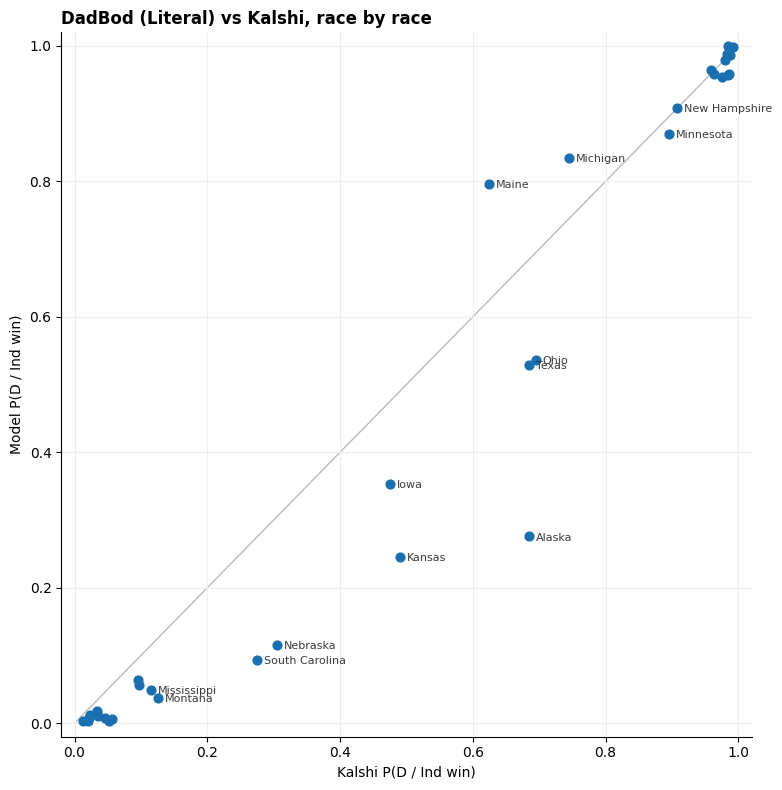

In [15]:
def plot_vs_kalshi(r, path=None):
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.plot([0, 1], [0, 1], color="#BBBBBB", lw=1, zorder=1)
    ax.scatter(r["kalshi_p"], r["p_dem"], s=40, color="#1A6FB0", zorder=3)
    for st, row in r.iterrows():
        if 0.1 < row["kalshi_p"] < 0.95 or abs(row["p_dem"] - row["kalshi_p"]) > 0.1:
            ax.annotate(st, (row["kalshi_p"], row["p_dem"]), xytext=(5, -3), textcoords="offset points", fontsize=8, color="#3C3C3C")
    ax.set_xlabel("Kalshi P(D / Ind win)")
    ax.set_ylabel("Model P(D / Ind win)")
    ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
    ax.grid(color="#EEEEEE", zorder=0)
    ax.spines[["right", "top"]].set_visible(False)
    ax.set_title("DadBod (Literal) vs Kalshi, race by race", loc="left", fontweight="bold")
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()


plot_vs_kalshi(RES["races"], S["OUT_DIR"] / "model_vs_kalshi.png")

### Seat distribution
Each bar is the share of simulated elections ending with that many Democratic seats. Blue = Democrats reach 51; red = they don't. The triangle on the axis marks the average.

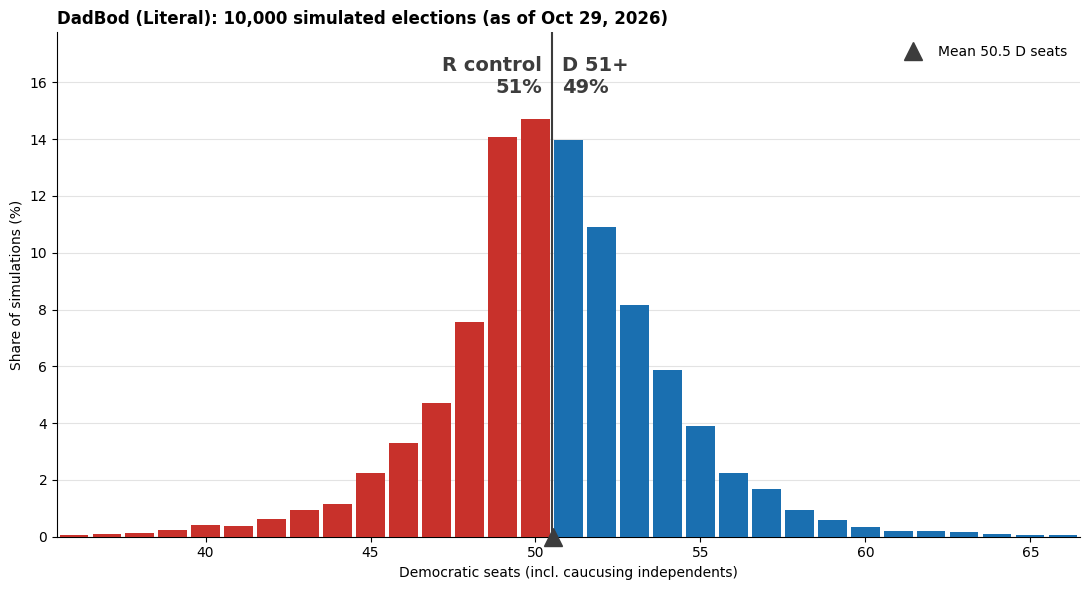

In [16]:
def plot_seat_distribution(d_seats, today, path=None):
    DEM_BLUE, REP_RED, INK = "#1A6FB0", "#C8312B", "#3C3C3C"
    need = S["D_SEATS_FOR_CONTROL"]
    seats, counts = np.unique(d_seats, return_counts=True)
    pct = 100 * counts / len(d_seats)
    p_dem = (d_seats >= need).mean()
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.bar(seats, pct, width=0.85, color=np.where(seats >= need, DEM_BLUE, REP_RED), zorder=3)
    ax.axvline(need - 0.5, color=INK, lw=1.5, zorder=2)
    ax.plot([d_seats.mean()], [0], marker="^", ms=13, color=INK, clip_on=False, zorder=5, ls="none",
            label=f"Mean {d_seats.mean():.1f} D seats")
    top = pct.max() * 1.15
    ax.text(need - 0.8, top, f"R control\n{1 - p_dem:.0%}", ha="right", va="top", color=INK, fontsize=14, fontweight="bold")
    ax.text(need - 0.2, top, f"D 51+\n{p_dem:.0%}", ha="left", va="top", color=INK, fontsize=14, fontweight="bold")
    ax.set_ylim(0, top * 1.05)
    ax.set_xlim(np.percentile(d_seats, 0.1) - 1.5, np.percentile(d_seats, 99.9) + 1.5)
    ax.set_xlabel("Democratic seats (incl. caucusing independents)")
    ax.set_ylabel("Share of simulations (%)")
    ax.grid(axis="y", color="#E3E3E3", zorder=0)
    ax.spines[["right", "top"]].set_visible(False)
    ax.legend(loc="upper right", frameon=False)
    ax.set_title(f"DadBod (Literal): {len(d_seats):,} simulated elections (as of {today:%b %d, %Y})", loc="left", fontweight="bold")
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()


plot_seat_distribution(RES["d_seats"], RES["today"], S["OUT_DIR"] / "seat_distribution.png")

### Save outputs
`headline.json` records the two numbers, the comparison, the national signals and the exact CONFIG, so every result can be traced to the settings that produced it.

In [17]:
out = S["OUT_DIR"]
race_table.to_csv(out / "race_table.csv")
RES["polls"].to_csv(out / "polls_used.csv", index=False)
RES["env"]["table"].to_csv(out / "national_signals.csv")
pd.Series(RES["d_seats"]).value_counts().sort_index().rename("n_sims").to_csv(out / "seat_distribution.csv", index_label="dem_seats")
headline = {"as_of": f"{RES['today']:%Y-%m-%d}", "run_at": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"),
            "variant": "Literal", **RES["summary"], "no_kalshi": RES_NO_KALSHI["summary"],
            "kalshi_p_control": k_ctrl, "kalshi_expected_seats": k_seats,
            "national": {"generic_ballot": RES["env"]["gb"], "net_approval": RES["env"]["net_approval"],
                         "undecided_share_U": RES["env"]["U"], "kalshi_approve_pct": RES["env"]["kalshi_approve_pct"]},
            "fundamentals": RES["fund_info"], "sources": SOURCE_STATUS, "config": CONFIG}
with open(out / "headline.json", "w") as f:
    json.dump(headline, f, indent=2, default=lambda x: x.item() if hasattr(x, "item") else str(x))
print(f"Saved race_table.csv, polls_used.csv, national_signals.csv, seat_distribution.csv/.png, model_vs_kalshi.png, "
      f"headline.json to {out}")

Saved race_table.csv, polls_used.csv, national_signals.csv, seat_distribution.csv/.png, model_vs_kalshi.png, headline.json to C:\Users\markg\OneDrive\Desktop\DACCS\2026_Midterm_Forecast\Models\DadBod_Model\DadBod_Literal\Output


### Standard export for `run_all.py`
Every model in the repo writes the same three files to `Output/standard/` so `run_all.py` can compare them without knowing how each model works: `summary.json` (headline numbers + key settings), `races.csv` (one row per race) and `seats.csv` (seat distribution). See the repo README.

In [18]:
STD = S["OUT_DIR"] / "standard"
STD.mkdir(parents=True, exist_ok=True)
_r = RES["races"]
pd.DataFrame({"state": _r.index, "p_dem": _r["p_dem"].values, "margin": _r["post_mean"].values, "sd": _r["post_sd"].values,
              "kalshi_p": _r["kalshi_p"].values, "n_polls": _r["n_polls"].values}).to_csv(STD / "races.csv", index=False)
_sh = pd.Series(RES["d_seats"]).value_counts(normalize=True).sort_index()
pd.DataFrame({"dem_seats": _sh.index, "share": _sh.values}).to_csv(STD / "seats.csv", index=False)
_c = CONFIG
_fund = (f"Literal (2024 {_c['W_STATE_2024']} : generic ballot {_c['W_GENERIC_BALLOT']} : approval {_c['W_APPROVAL']})"
         if "W_STATE_2024" in _c else f"Swing (generic ballot {_c['W_GENERIC_BALLOT']} : approval {_c['W_APPROVAL']})")
STANDARD = {
    "model": "DadBod", "variant": "Literal", "run_at": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"),
    "as_of": f"{RES['today']:%Y-%m-%d}", **RES["summary"], "n_sims": int(_c["N_SIMS"]),
    "kalshi_p_control": k_ctrl, "kalshi_expected_seats": k_seats, "sources": SOURCE_STATUS,
    "key_settings": {
        "Poll source": "VoteHub API",
        "Poll age": f"last {_c['WINDOW_DAYS']} days, weight 1.0 -> {_c['WINDOW_OLDEST_WEIGHT']}",
        "Polls : fundamentals : Kalshi": f"{_c['W_POLLS']} : {_c['W_FUNDAMENTALS']} : {_c['W_KALSHI']} (polls x reliability)",
        "Poll reliability (thin races)": str(_c["POLL_RELIABILITY"]),
        "Fundamentals": _fund,
        "Incumbency": f"{_c['INCUMBENCY_PTS']:g} pts",
        "LV : RV : A": " : ".join(f"{v:g}" for v in _c["POPULATION_WEIGHTS"].values()),
        "Flooding penalty": f"1/k^{_c['FLOOD_EXPONENT']}",
        "House effects": "on" if _c["HOUSE_EFFECTS"] else "off",
        "Ungraded pollsters": _c["UNRATED_POLLSTERS"],
        "National signals": f"VoteHub polls + Kalshi averages (= {_c['NAT_KALSHI_POLL_EQUIV']} polls)",
        "Kalshi races": "input + comparison (found automatically)",
        "Source errors": f"correlated (rho {_c['SOURCE_ERROR_CORR']})" if _c["CORRELATED_ERRORS"] else "independent",
    },
}
with open(STD / "summary.json", "w") as f:
    json.dump(STANDARD, f, indent=2, default=lambda x: x.item() if hasattr(x, "item") else str(x))
print(f"Standard export -> {STD}")

Standard export -> C:\Users\markg\OneDrive\Desktop\DACCS\2026_Midterm_Forecast\Models\DadBod_Model\DadBod_Literal\Output\standard


---
**Next:** open **`Model Testing.ipynb`** in this folder. It re-runs this notebook and then checks the data, flags thin or stale inputs, stress-tests every setting, and charts how the forecast has moved week by week.